# Project Report: Pulse Propagation



## Introduction
In modern telecommunications, data is transmitted through optical fibers via the propagation of short light pulses. This project investigates the dispersion and broadening effects that occur when a Gaussian pulse travels through a single-mode optical fiber.

Since a Gaussian pulse is composed of different frequency components that travel at different velocities in a dispersive medium, the pulse inevitably broadens in time. In this report, we use Python to numerically model and visualize:
1. A regular Gaussian pulse in a nondispersive medium (without chirp).
2. The effects of broadening and chirp on the pulse envelope and its electrical field (carrier wave).
3. The impact of varying parameters on the pulse shape at sequential time intervals.

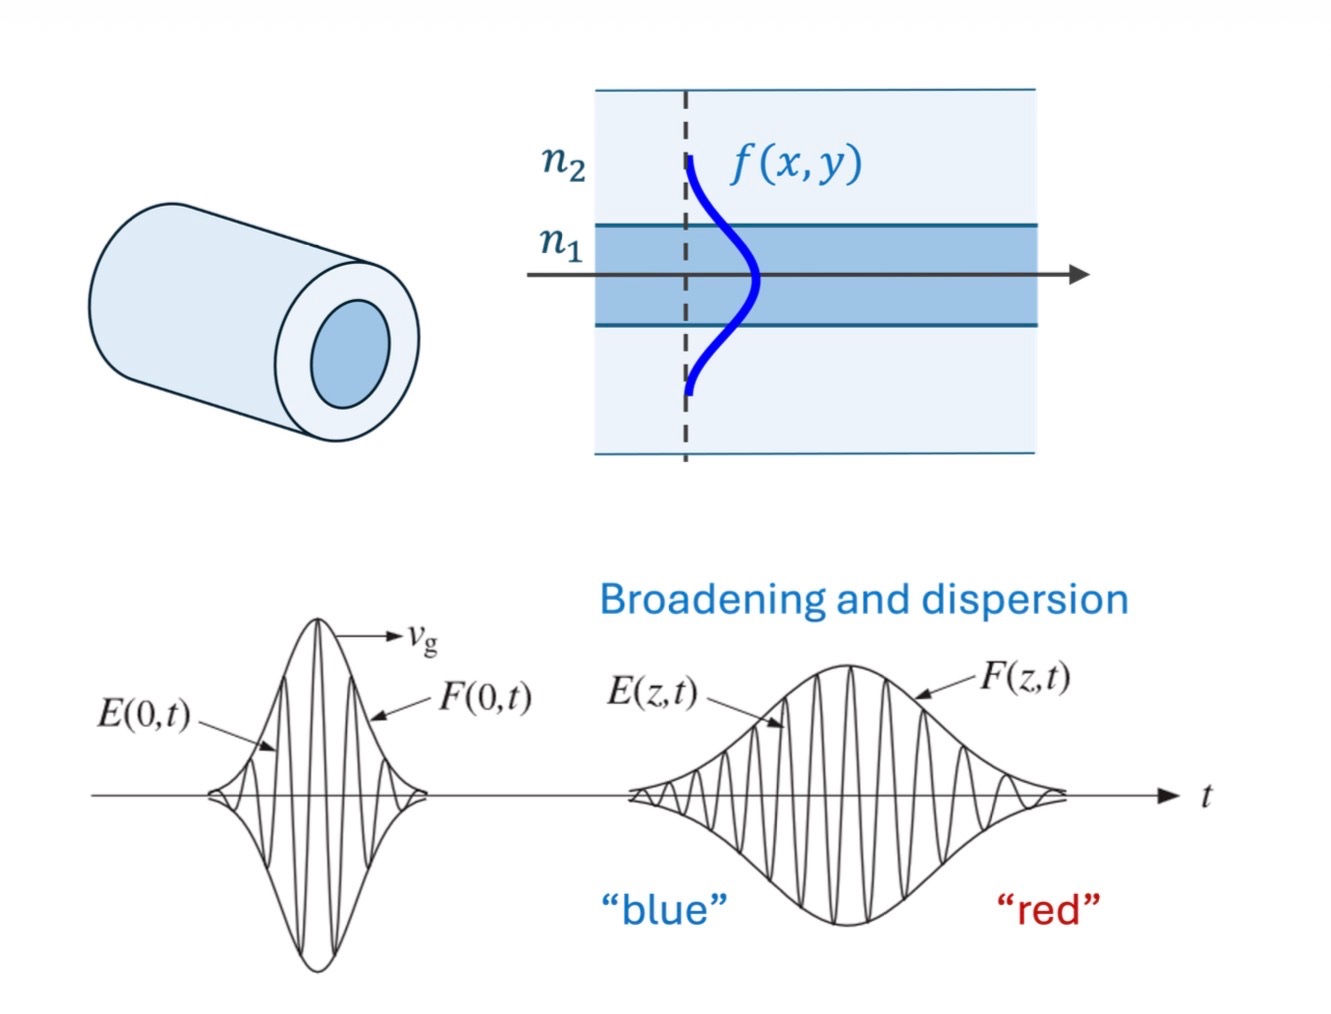

## Mathematical Model and Parameter Definitions

The propagation of a chirped Gaussian pulse in a dispersive optical fiber is modeled using the analytical solution of the pulse envelope. 

$$\mathrm{Intensity(z, t)} = (A_0^2 / b_f(z))  \exp( -t^2 / (T_0^2 * b_f(z)^2))$$

To fully explain the simulation parameters, their mathematical formulas and physical units are defined below:

1. Dispersion Length ($\mathrm{L_D}$)       
The length scale over which Group Velocity Dispersion (GVD) effects become dominant is defined by:
$$L_D = \frac{T_0^2}{|\beta_2|}$$
Unit: Kilometers (km) or Meters (m)

2. Group Velocity Dispersion Parameter ($\mathrm{beta_2}$)
It determines the sign and magnitude of the dispersion pulse experiences per unit length.
Unit: Picoseconds squared per kilometer ($\mathrm{ps^2/km}$)

3. Initial Pulse Width ($\mathrm{T_0}$)
Represents the half-width of the pulse at 1/e intensity point.
Unit: Picoseconds (ps)

4. Normalized Distance (z)
The physical propagation distance scales by dispersion length:
$$z = \frac{z_{physical}}{L_D}$$
Unit: Dimensionless

5. Initial Chirp Parameter (C)
Represents the phase modulation or the frequency chirp imposed on the inital pulse.
Unit: Dimensionless

6. Pulse Broadening Factor ($\mathrm{b_f}$)
The ratio showing how much the pulse widens as a function of normalized distance z:
$$b_f(z) = \sqrt{(1 + s C z)^2 + z^2}$$
Unit: Dimensionless

7. Sign of Dispersion (s)
An indicator variable where s = +1 represents the anomalous dispersion regime and s = -1 represent the normal dispersion regime.
Unit: Dimensionless

### Step 1: Regular Gaussian Pulse (No Chirp, Nondispersive Medium)

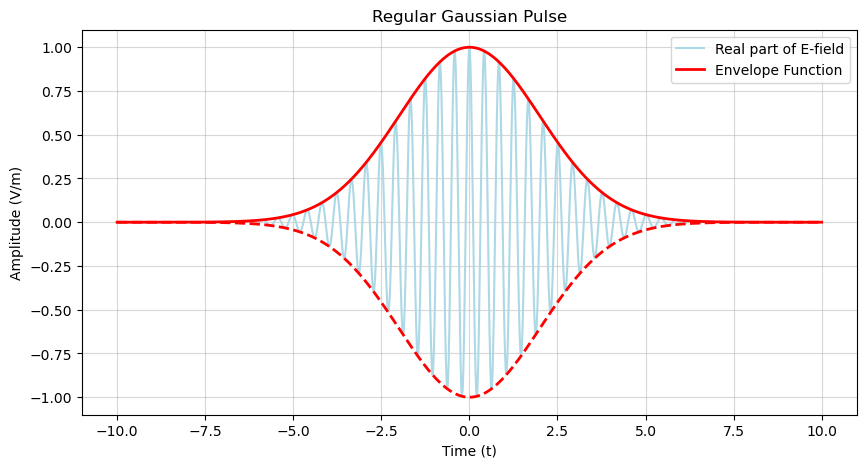

In [4]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt

# PARAMETERS
A0 = 1.0       # Peak amplitude 
T0 = 2.0       # Initial pulse width
w0 = 15.0      # Carrier frequency

# Create a time array from -10 to 10 with 1000 points
t = np.linspace(-10, 10, 1000)

# CALCULATIONS (z=0, C=0)
# 1. Envelope function
# Formula simplifies to basic Gaussian when there is no dispersion and no chirp
envelope = A0 * np.exp(- (t**2) / (2 * T0**2))

# 2. Real part of the Electric Field 
electric_field = envelope * np.cos(w0 * t)

# PLOTTING
plt.figure(figsize=(10, 5))

# Plot the real part of the electric field (rapidly oscillating wave)
plt.plot(t, electric_field, label='Real part of E-field', color='lightblue')

# Plot the envelope function (the outline of the pulse)
plt.plot(t, envelope, label='Envelope Function', color='red', linewidth=2)

# Plot the negative envelope for a complete outline
plt.plot(t, -envelope, color='red', linewidth=2, linestyle='--')

# Formatting the plot
plt.title('Regular Gaussian Pulse')
plt.xlabel('Time (t)')
plt.ylabel('Amplitude (V/m)')
plt.grid(True, alpha=0.5)
plt.legend()

# Show the plot
plt.show()


### Step 2: Adding Chirp and Broadening (Dispersion)
In this step, we introduce the propagation distance ($z$) and the initial chirp parameter ($C$).
Using the Agrawal formula provided in the project description, we calculate the complex optical field $A(z,t)$.
The broadening factor $b_f(z)$ and the new chirp $C_1(z)$ cause the pulse to widen and its amplitude to drop as it travels throught the fiber.

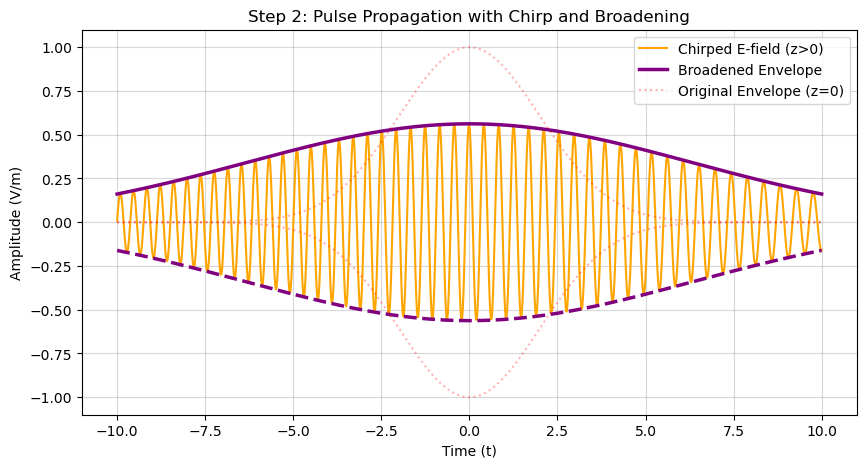

In [5]:
### STEP 2 PARAMETERS
# Propagation distance and chirp parameters based on Agrawal's formula
z = 1.0       # Distance travelled in the fiber (z axis)
C = 2.0       # Initial chirp parameter 
s = 1.0       # Sign of dispersion parameter (+1 for normal dispersion)

# CALCULATIONS
# 1. Broadening factor (b_f) and new chirp (C_1) formulas from the document
b_f = np.sqrt((1 + s * C * z)**2 + z**2)
C1 = C + s * (1 + C**2) * z

# 2. Phase shift from the arctan term in the formula
phi = 0.5 * np.arctan(z / (1 + C * z))

# 3. Complex Optical Field A(z,t)
# In Python, we use '1j' to represent the complex imaginary unit 'i'
term1 = - ((1 + 1j * C1) * t**2) / (2 * (T0**2) * (b_f**2))
A_zt = (A0 / np.sqrt(b_f)) * np.exp(term1 + 1j * phi)

# 4. Extracting the Envelope and Electric Field
# The envelope is the magnitude (absolute value) of the complex optical field
envelope_broadened = np.abs(A_zt)

# The real electric field includes the carrier wave (w0 * t)
electric_field_chirped = np.real(A_zt * np.exp(1j * w0 * t))

# PLOTTING
plt.figure(figsize=(10, 5))

# Plot the new chirped carrier wave 
plt.plot(t, electric_field_chirped, label='Chirped E-field (z>0)', color='orange')

# Plot the new broadened envelope
plt.plot(t, envelope_broadened, label='Broadened Envelope', color='purple', linewidth=2.5)
plt.plot(t, -envelope_broadened, color='purple', linewidth=2.5, linestyle='--')

# Plot the original envelope from Step 1 as a transparent background line for comparison
plt.plot(t, envelope, label='Original Envelope (z=0)', color='red', linestyle=':', alpha=0.3)
plt.plot(t, -envelope, color='red', linestyle=':', alpha=0.3)

# Formatting
plt.title('Step 2: Pulse Propagation with Chirp and Broadening')
plt.xlabel('Time (t)')
plt.ylabel('Amplitude (V/m)')
plt.grid(True, alpha=0.5)
plt.legend()

# Show the plot
plt.show()


### Step 3: Parameter Adjustment and Sequential Evolution
In this final step, we observe the pulse at sequential propagation distances ($z = 0, 1, 2, 4$).
By adjusting the distance parameter, we can clearly see the impact of dispersion and chirp:
As the pulse travels further into the fiber, the broadening factor $b_f(z)$ increases continuously. Consequently the pulse spreads out more in time, and its peak amplitude drops significantly to conserve energy.

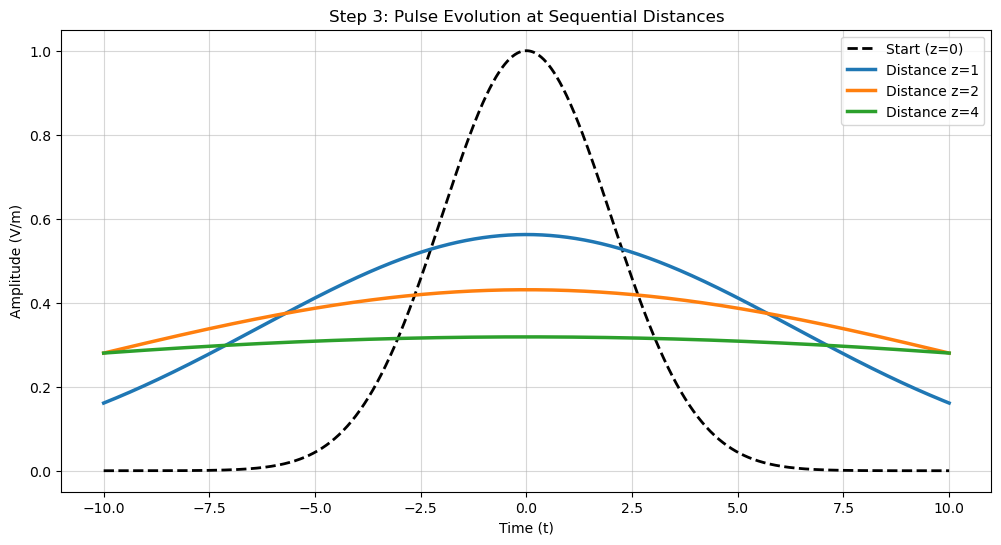

In [6]:
##### STEP 3: SEQUENTIAL PLOTS
# We will plot the pulse envelope at 4 different propagation distances to see the evolution
distances = [0, 1, 2, 4]    # Different z values (sequential points)
C_param = 2.0               # Keep initial chirp constant
s_param = 1.0               # Normal dispersion (+1)

plt.figure(figsize=(12, 6))

# Loop throught each distance and calculate the new pulse shape
for z_val in distances:
    # 1. Recalculate broadening factor and phase for current z
    bf_val = np.sqrt((1 + s_param * C_param * z_val)**2 + z_val**2)
    C1_val = C_param + s_param * (1 + C_param**2) * z_val
    phi_val = 0.5 * np.arctan(z_val / (1 + C_param * z_val))

    # 2. Calculate Complex Optical Field
    term1_val = -((1 + 1j * C1_val) * t**2) / (2 * (T0**2) * (bf_val**2))
    A_val = (A0 / np.sqrt(bf_val)) * np.exp(term1_val + 1j * phi_val)

    # 3. Extract the envelope (absolute magnitude)
    env_val = np.abs(A_val)

    # 4. Plot the envelope for this specific distance 
    # Using different linewidths/styles to make it look professional
    if z_val == 0:
        plt.plot(t, env_val, label=f'Start (z={z_val})', color='black', linestyle='--', linewidth=2)
    else:
        plt.plot(t, env_val, label=f'Distance z={z_val}', linewidth=2.5)

# Formatting the final plot
plt.title('Step 3: Pulse Evolution at Sequential Distances')
plt.xlabel('Time (t)')
plt.ylabel('Amplitude (V/m)')
plt.grid(True, alpha=0.5)
plt.legend()

# Show the plot
plt.show()   

## Summary and Conclusion

In this project, the mathematical model of Gaussian pulse propagation inside a single-mode dispersive optical fiber was successfully simulated based on Govind Agrawal's formulations.

Our simulation results clearly demonstrate that:
1. In a non-dispersive medium without chirp (Step 1), the pulse maintains its original shape and constant carrier frequency.
2. In a dispersive medium (Step 2 & 3), the pulse undergoes time-domain broadening due to Group Velocity Dispersion (GVD).
3. The introduction of an initial chirp ($C$) induces a frequency shift across the pulse (chirping effect), causing the leading and trailing edges of the pulse to shift towards different freguencies (red and blue shifts).
4. Plotting the pulse at sequential distances dynamically illustrated how broadening accumulates as the propagation distance ($z$) increases.